Before I begin, I'd like to acknowledge that due to my limited prerequisite knowledge of machine learning and its classical methods, I have relied heavily on external resources in completing this task, mainly from [Qiskit Ecosystem](https://qiskit-community.github.io/qiskit-machine-learning/) which has multiple [contributors](https://github.com/qiskit-community/qiskit-machine-learning/graphs/contributors) working on quantum machine learning.

I recommend checking out their work for more in-depth understanding and additional resources on the topic, as well as a soft introduction to [PyTorch](../PyTorch) in my parent repository. Don't worry if it seems overwhelming at first; with time and practice, you'll get the hang of it! I'll introduce the basic concepts and provide code examples to help you get started with quantum machine learning using Qiskit. 

Also, this notebook **requires a Python Version <= 3.11.x,** because of some dependencies that are not yet compatible with Python 3.12.x and higher. Apologies for any inconvenience, I tried really hard with my own 3.12.6 version. I strongly recommend using a virtual environment manager like `venv` or `conda` to create an isolated environment with the required Python version for this notebook.

Don't worry if you installed the libraries we used in earlier notebooks like qiskit, numpy, matplotlib in your (incompatible here) version, I've got you covered! This is basically everything I used the last 4 notebooks all in one line. Don't forget to set the correct Python version in your environment as your JuPyter kernel.

In [1]:
%pip install -U qiskit qiskit_ibm_runtime qiskit_aer numpy matplotlib pylatexenc scipy time

ERROR: Ignored the following versions that require a different python version: 1.10.0 Requires-Python >=3.8,<3.12; 1.10.0rc1 Requires-Python >=3.8,<3.12; 1.10.0rc2 Requires-Python >=3.8,<3.12; 1.10.1 Requires-Python >=3.8,<3.12; 1.11.0 Requires-Python >=3.9,<3.13; 1.11.0rc1 Requires-Python >=3.9,<3.13; 1.11.0rc2 Requires-Python >=3.9,<3.13; 1.11.1 Requires-Python >=3.9,<3.13; 1.11.2 Requires-Python >=3.9,<3.13; 1.11.3 Requires-Python >=3.9,<3.13; 1.21.2 Requires-Python >=3.7,<3.11; 1.21.3 Requires-Python >=3.7,<3.11; 1.21.4 Requires-Python >=3.7,<3.11; 1.21.5 Requires-Python >=3.7,<3.11; 1.21.6 Requires-Python >=3.7,<3.11; 1.26.0 Requires-Python >=3.9,<3.13; 1.26.1 Requires-Python >=3.9,<3.13; 1.6.2 Requires-Python >=3.7,<3.10; 1.6.3 Requires-Python >=3.7,<3.10; 1.7.0 Requires-Python >=3.7,<3.10; 1.7.1 Requires-Python >=3.7,<3.10; 1.7.2 Requires-Python >=3.7,<3.11; 1.7.3 Requires-Python >=3.7,<3.11; 1.8.0 Requires-Python >=3.8,<3.11; 1.8.0rc1 Requires-Python >=3.8,<3.11; 1.8.0rc2 Requi

***

# To Kickstart: Machine Learning

What is Machine Learning? Why has it attracted so much attention in recent years? In simple terms, it's like teaching a computer to recognize patterns and make informed choices based on those patterns. The simplest example of this in practice is spam email detection in mail services like Gmail, and generative AI tools like ChatGPT. It does this by applying algorithms to datasets. From a physicist’s perspective, machine learning is simply parameter estimation from data under a model class.

Moving up a level of difficulty, I can present the formal definition; Machine Learning is a subset of AI that deals with the development of statistical algorithms and models that can learn from 'training data' to make predictions on 'unseen data', thus perfoming tasks without being explicitly programmed for each specific task. As you can guess, a strong background and understanding of statistics and mathematical optimization is required to fully grasp the concepts of machine learning.

Now, this isn't a machine learning course, so I won't bore you with all the nitty-gritty details of neural networks and other topics which typically star in classical machine learning. Instead, I'll define exactly what Quantum Machine Learning (QML) is, and how it differs from classical machine learning. Basically, what we're doing is $$\text{minimize}_\theta\,\,\mathcal L(\langle O_{\psi(x,\theta)}\rangle)$$ where $\mathcal L$ is a loss function to minimize, $O$ is an observable, and $\psi(x,\theta)$ is a parameterized quantum state dependent on input data $x$ and the minimizer parameters $\theta$.

It's understandable that one might think that QML describes quantum computers engaged in machine learning tasks, but it's more nuanced than that. This definition is quite narrow and limiting, as we physics enthusiasts are naturally more concerned with employing machine learning techniques to **solve quantum problems** and **enhance quantum computing capabilities**.

Please keep this distinction in mind as we proceed. Quantum Machine Learning is a multidisciplinary field that combines principles from quantum computing and machine learning to develop algorithms that can use unique properties of quantum mechanics to work towards quantum supremacy in machine learning tasks.

# Add the 'Quantum' in there:

A generic problem can be solved for the first time on a quantum computer, and then subsequently people find a way to do it on a classical supercomputer. This cycle of classical and quantum computing pushing each other to their limits will likely go on and on. There are specific problems where quantum supremacy is achievable, given progress in areas such as reduction of errors and the number of available physical qubits.

QML might plausibly include quantum mechanics in either the data or algorithmic sides, or both. We'll mostly restrict ourselves to discussions of **quantum algorithms** applied to **classical data.** One reason for this is that ML problems with classical data are already so well studied and widely available, and another reason is the lack of QRAM. Without the ability to store large amounts of quantum data on a relatively long timescale, methods that begin with quantum data are still fairly far from applicability to industry. It is also unclear how to 'quantumly-access' classical data in an efficient manner.

Quantum algorithms can offer an exponential speed-up over classical algorithms for **very specific problems** that are classically hard, and well-suited to quantum algorithms. They aren't a magic solution for all machine learning problems. Higher dimensionality of quantum states can potentially allow for more complex data representations, which might help in capturing intricate patterns in data, according to Cover's Theorem:

> 'A complex pattern-classification problem, cast in a high-dimensional space nonlinearly, is more likely to be linearly separable than in a low-dimensional space.'

A common goal in QML is to find a mapping from the lower-dimensional set of features into a higher-dimensional space, that effectively separates datapoints so we can use the mapping to classify new datapoints. However, increased dimensions in quantum computing cannot be a sufficient condition for computational power over classical alternatives, and there are nuances and caveats to consider.

Learning algorithms often depend only on inner products, which makes quantum states—defined intrinsically by inner products—natural candidates for feature spaces. The *kernel trick* is a method used in classical machine learning to implicitly map data into higher-dimensional spaces **without** explicitly computing the coordinates in that space. Quantum computers can naturally compute inner products of quantum states, even when those states exist in exponentially large Hilbert spaces.

You might recall that I mentioned the Hilbert Space not too long ago in my introductory notebook. This space, being exponentially larger for quantum systems compared to classical ones, indeed provides a fertile ground for representing complex data structures. Let's try to mathematically explore the implications. 

Cover's theorem in principle, suggests that for a set of real datapoints $x_i\in\mathbb R^d$, where $d$ is a given dimension, there exists a non-linear mapping $$\zeta:\mathbb R^d\to\mathbb R^D$$ into a higher-dimensional space such that the transformed points $\zeta(x_i)$ are linearly separable with high probability, provided that $D>>d$. Also, the probability that some binary labels $y_i\in\{-1,1\}$ associated with the points $x_i$ can be separated by a hyperplane in the 
$\zeta$-space grows rapidly with $D$.

Since quantum computers can represent data in a Hilbert space of dimension $2^n$ for $n$ qubits, mapping a quantum state $\ket{\zeta}$ to a higher-dimensional space is inherently feasible, through what's called a *Quantum Feature Map.* This map encodes classical data into quantum states, and establishes mathematical continuity with Cover's theorem and ML:

$$\begin{align*}\ket{\zeta(x)} = \hat{\mathscr U}_\zeta(x)\ket{0}^{\otimes n}&&x\to\ket{\zeta(x)}\in\mathbb C^{2^n}\end{align*}$$

# So how does Qiskit help?

So, does the quantum computer 'learn' anything during this process? Not really. The quantum computer itself does not perform model training. It evaluates inner products between quantum states. All learning happens classically; hence the name 'quantum-enhanced' machine learning. The quantum computer is used as a subroutine to compute inner products in high-dimensional spaces that would be infeasible to compute classically.

What 'map' I described earlier is implemented in QML through a *Quantum Kernel Method.* For each classical datapoint $x_i$ you choose a parameterized unitary $\hat{\mathscr U}$ embedding:

$$\ket{\zeta(x_i)} = \hat{\mathscr U}(x_i)\ket{0}^{\otimes n}$$

A *Kernel Function* $K(x_i,x_j)$ computes the inner product between two quantum states. Why? It tells you how similar every pair of data points is, according to some meaningful similarity measure, similar to classical ML. Think of it like a separator that helps you distinguish between different classes of data points. These functions make up the *Kernel Matrix,* whose elements are

$$K_{ij}\equiv K(x_i,x_j) = |\langle \zeta(x_i)|\zeta(x_j)\rangle|^2$$

To recap terminology, $\zeta$ is the quantum feature map that encodes classical data into quantum states, and $K$ is the kernel function that computes the similarity between pairs of these quantum states. The kernel matrix $K_{ij}$ contains all pairwise similarities, and is an inner product matrix in the quantum feature space of $\dim(\mathcal H)=2^n$.

If you're interested in diving deeper into how inner products are computed on quantum computers, I recommend checking out the [Qiskit Machine Learning documentation](https://qiskit-community.github.io/qiskit-machine-learning/) for more detailed explanations and examples. I also want to go on a little tangent to explain **why** inner products are the similarity measure of choice in QML specifically.

Inner products measure both alignment and magnitude between vectors, specifically through relative phase and the norm (always positive). They also measure measurement similarity, so a perfect overlap $\braket{x_i|x_i}=1$ means that two quantum states will yield identical measurement outcomes across all bases. Both geometric and measurement similarities are satisfied, along with preservation of norm and alignment.

I know this is a lot, and you haven't seen a single line of code yet. But hang in there! 

# Primer on Quantum Machine Learning with Qiskit

Now we're talking. In this tutorial, I'll guide you through one specific realm of quantum machine learning, a framework in which the feature representation is quantum, while optimisation remains classical. We'll be using Qiskit's `qiskit-machine-learning` library to implement a quantum classifier using a quantum kernel method. It should be eventually supported by Python 3.12+, but as of yet, 3.11 or earlier is recommended (As of 2025-11).

In [2]:
%pip install qiskit-machine-learning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 7.8 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 8.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [qiskit-machine-learning]-learn]
Note: you may need to restart the kernel to use updated packages.


One more module for our toolkit is `jax`, which is a library for implementing machine learning algorithms and optimization routines. We'll use this library to implement and optimize our quantum machine learning model.

It should be compatible with Qiskit 2.x+ and NumPy 2.0+, but please ensure you have the latest version installed to avoid any compatibility issues. You can install them using pip. I'm assuming a standard CPU installation here; if you have a CUDA-compatible and powerful GPU, please refer to the official documentation for installation instructions, the rest of the code should work the same.

In [3]:
%pip install --no-cache-dir 'jax[cpu]'
%pip install --upgrade jaxopt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 5.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 10.9 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 562.6/562.6 kB 11.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [jax]3/4 [jax]ib]
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Now your device (CPU/GPU if applicable) should be ready to go with JAX. You can verify this by running the following code snippet:

In [4]:
import jax, jax.numpy as jnp
from jaxopt import ProjectedGradient

print('JAX device:', jax.default_backend())

JAX device: cpu


In [6]:
import numpy as np, matplotlib.pyplot as plt, time, scienceplots
plt.style.use(['science', 'notebook', 'grid', 'dark_background'])

# OTHER QISKIT IMPORTS

from qiskit import *
from qiskit.visualization import *
from qiskit.quantum_info import *
from qiskit.circuit.library import *
from qiskit_ibm_runtime import Sampler, QiskitRuntimeService

from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute

# DRAW STYLE (default mpl dark), check https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits and 
# https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.circuit_drawer for more styles

def draw_circuit(qc):
    return qc.draw(output = 'mpl', style = 'iqp-dark')

I won't go in depth into tensors, higher-dimensional arrays, and neural networks here in this series, but I recommend checking out my [PyTorch primer](../PyTorch) in the same repository for a gentle introduction to classical ML methods. Remember, that this is completely optional for this tutorial, as we will be using purely quantum methods and I'd like a low barrier to entry.

Qiskit machine learning's library provides a suite of tools and algorithms specifically designed for quantum machine learning tasks. It includes implementations of quantum classifiers, regressors, and clustering algorithms, as well as utilities for data encoding and quantum feature maps.

Before we begin, a checklist:

1. Choose a dataset
2. Define a quantum feature map
3. Compute a kernel matrix
4. Train a classical SVM on that kernel (I'll talk about this in that section)
5. Evaluate performance

I'll guide you through each step with code examples and explanations with easy math. Let's get started!

## 1. Data Encoding

An 'QC-encodable' dataset is simply a set of $M$ classically labeled datapoints $\{(x_i,y_i)\}_{i=1}^M$, where each $x_i\in\mathbb R^d$ is a $d$-dimensional (what we'll call) feature vector, and $y_i\in\{-1,1\}$ is a binary label. The goal is to classify new datapoints based on the patterns learned from this dataset.

Let $\xi$ be the feature mapping of $x_i$ into a quantum state $\ket{\xi(x_i)}$ in a Hilbert space $\mathcal H$ of dimension $2^n$, where $n$ is the number of qubits used for encoding. The mapping is performed using a parameterized unitary operation $\hat U_\xi(x_i)$ such that $$\ket{\xi(x_i)} = \hat U_\xi(x_i)\ket{0}^{\otimes n}$$

This should ring a few bells as to how we could implement this in Qiskit. We have to choose an encoding scheme, say binary. Although, Qiskit itself provides several built-in feature maps for this purpose, such as `ZZFeatureMap`, `PauliFeatureMap`, and `ZFeatureMap`.

We'll do binary first, as it's the simplest to understand (and if you recall, we've done it before). A tuple $(5, 2, 3)$ could be encoded into a (?)-qubit quantum state? Try it out!

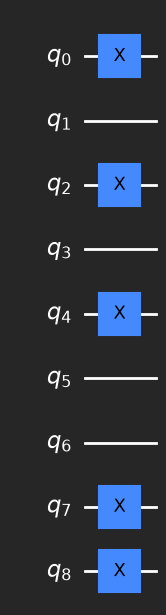

In [ ]:
x1 = 5
x2 = 2
x3 = 3

config = [int(b) for b in format(x1, '03b')] + ...
qc_binenc = QuantumCircuit(3 + ...)
                           
for i, bit in enumerate(config):
    if bit == 1:
        qc_binenc.x(i)

draw_circuit(qc_binenc)

Don't worry if the order's reversed, it's supposed to be! Qiskit ordering is little-endian, meaning the least significant bit is on the left.

There are other ways of manual encoding. The ones we'll cover are *amplitude encoding*, *angle encoding, dense angle encoding,* and *phase encoding.*

In [10]:
data = np.array([x1, x2, x3])

Take our dataset $(x_1, x_2, x_3)=(5, 2, 3)$ again. Amplitude encoding represents data points as, as guessed, amplitudes of quantum states. Note that for this, a state would've to be normalized. The number of qubits required is determined by the formula $n=\lceil \log_2(d)\rceil$, where $d$ is the dimension of the data point and $\lceil \cdot \rceil$ is the ceiling function. Why the log? Look at the base, and think about how we could simplify the representation. 

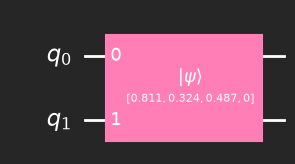

In [11]:
def amplitude_encoding(data):
    
    norm = np.linalg.norm(data)
    normalized_data = data / norm
    
    num_qubits = int(np.ceil(np.log2(len(data))))
    padded_data = np.pad(normalized_data, (0, 2**num_qubits - len(data)), 'constant')
    
    qc = QuantumCircuit(num_qubits)
    qc.initialize(padded_data, range(num_qubits))
    
    return qc

qc_ampenc = amplitude_encoding(data)
draw_circuit(qc_ampenc)

The subtext of the 2-qubit gate is sure enough, the 3 normalized amplitudes of the 3 data points, and one null amplitude to make up the 4 required for 2 qubits. 

Statevector([0.81110711+0.j, 0.32444284+0.j, 0.48666426+0.j,
             0.        +0.j],
            dims=(2, 2))


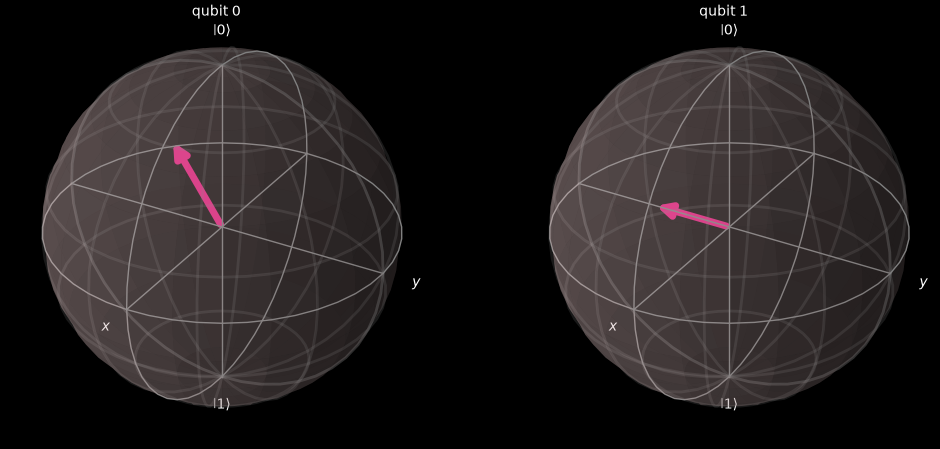

In [12]:
statevector = Statevector.from_instruction(qc_ampenc)
print(statevector)
plot_bloch_multivector(statevector)

Now, onto angle encoding. Angle encoding operates through a circuit of rotation gates, where we have the choice of rotation axis. Each feature of the data point is mapped to a rotation angle of a qubit. For our dataset $(5, 2, 3)$, we can use Y-rotations to encode the values.

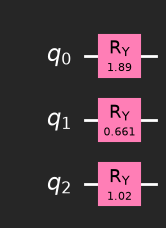

In [13]:
def angle_encoding(data):
    
    num_qubits = len(data)
    qc = QuantumCircuit(num_qubits)
    
    for i, value in enumerate(data):
        qc.ry(2 * np.arcsin(value / np.linalg.norm(data)), i)
    
    return qc

qc_angleenc = angle_encoding(data)
draw_circuit(qc_angleenc)

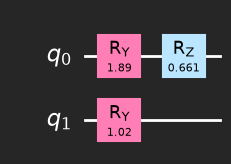

In [14]:
def dense_angle_encoding(data):
    num_qubits = int(np.ceil(len(data) / 2))
    qc = QuantumCircuit(num_qubits)
    
    for i in range(num_qubits):
        if 2 * i < len(data):
            qc.ry(2 * np.arcsin(data[2 * i] / np.linalg.norm(data)), i)
        if 2 * i + 1 < len(data):
            qc.rz(2 * np.arcsin(data[2 * i + 1] / np.linalg.norm(data)), i)
    
    return qc

qc_dense_angleenc = dense_angle_encoding(data)
draw_circuit(qc_dense_angleenc)

The difference between angle encoding and dense angle encoding is that in the latter, we can use **multiple** rotation axes per qubit to encode more information. Here, you can see that we used both Y and Z rotations on a single qubit to encode two features of the data point. Notably, this can reduce the number of qubits required for encoding, which is beneficial given the current limitations in qubit availability and coherence times in quantum hardware.

Statevector([0.48331997+0.j, 0.6702442 +0.j, 0.16577738+0.j,
             0.22989187+0.j, 0.2692508 +0.j, 0.37338367+0.j,
             0.09235226+0.j, 0.12806954+0.j],
            dims=(2, 2, 2))


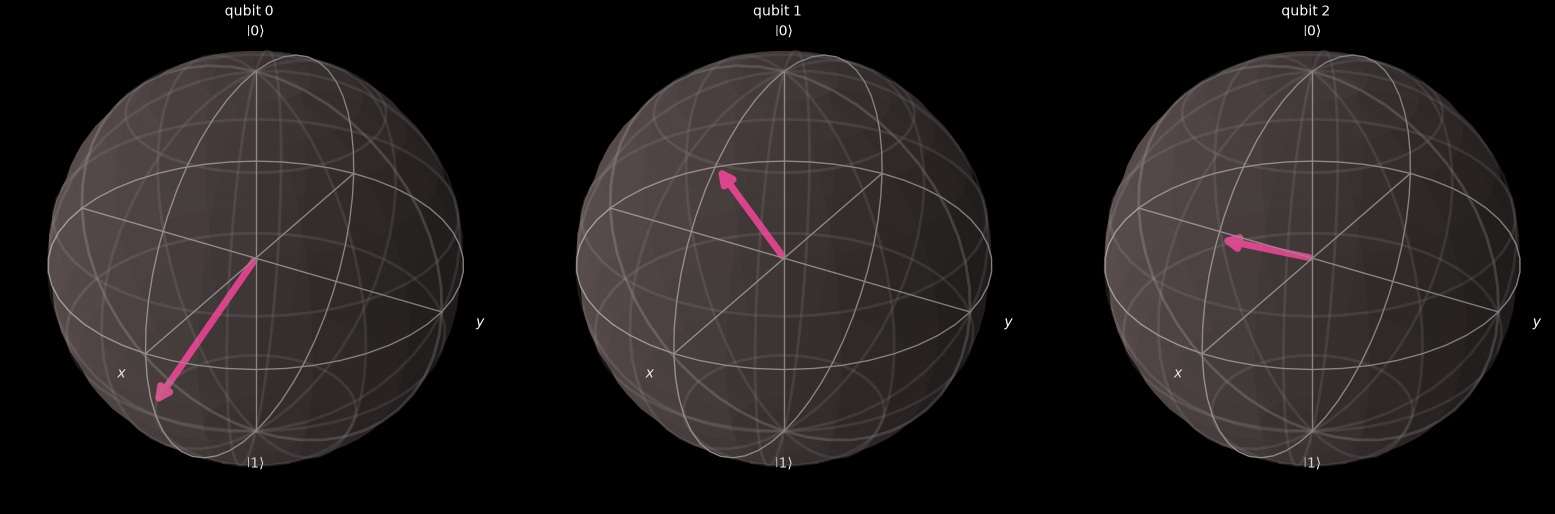

In [15]:
statevector_angle = Statevector.from_instruction(qc_angleenc)
print(statevector_angle)
plot_bloch_multivector(statevector_angle)

Statevector([0.48331997-0.16577738j, 0.6702442 +0.22989187j,
             0.2692508 -0.09235226j, 0.37338367+0.12806954j],
            dims=(2, 2))


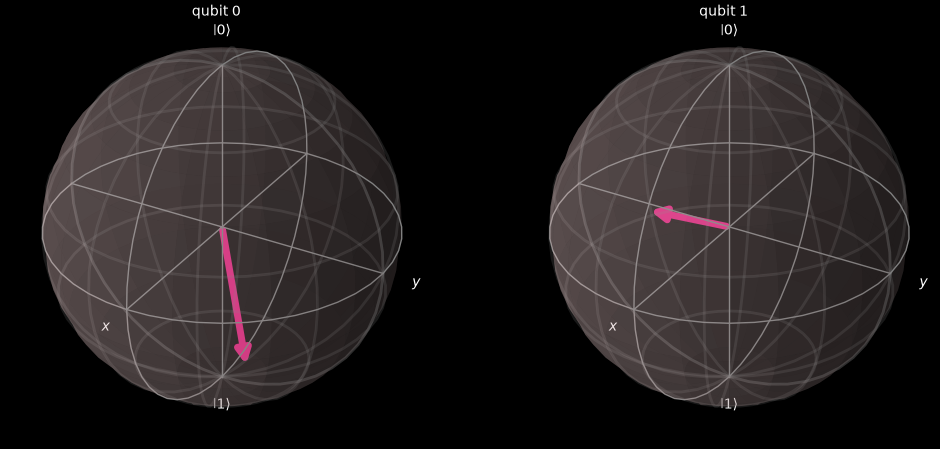

In [16]:
statevector_dangle = Statevector.from_instruction(qc_dense_angleenc)
print(statevector_dangle)
plot_bloch_multivector(statevector_dangle)

There you have it! You can decide for yourselves which encoding scheme works best for your specific dataset and problem. You can call the helper functions I provided inside the notebook to visualize the statevectors and Bloch spheres for each encoding method. From here on out though, I'll be using Qiskit's built-in feature maps for simplicity.

You might be wondering, which of these is the most appropriate for a general large dataset? You might think that amplitude encoding is the best, since it uses the least number of qubits and of course, is fed by our own normalized dataset as-is. However, this type of encoding scales with $\mathcal O(d=2^n)$ instead of $\mathcal O(d=n)$ like the others, meaning that for large datasets, it's extremely inefficient.

**Dense angle encoding** is often preferred and 'standard' (in some sense in non-native Qiskit implementations) because it trades qubits for time, balancing qubit efficiency and expressiveness well. It scales linearly with circuit depth and layers, and polynomially with the number of gates. (Remember that we had one rotation per feature only?). What makes it better than standard angle encoding is that we simply have more rotations per qubit, allowing us to capture more complex relationships in the data in those rotation axes.

## 2. Quantum Feature Map

As I explained earlier, a quantum feature map is a way to encode classical data into quantum states. In Qiskit, we can use built-in feature maps like `ZZFeatureMap`, `PauliFeatureMap`, and `ZFeatureMap`. These maps apply a series of quantum gates to transform the initial state into a state that represents the input data.

I abbreviate those three as ZFM, ZZFM, and PFM respectively. I'll also go briefly in depth about how they differ, so you can understand their unique applicabilities. 

1. ZFM basically encodes $x_i\to\exp(iZx_i)$, applying Z-rotations successively in the fashion of angle encoding. It's simple and efficient, but may not capture complex correlations in the data.
2. ZZFM introduces **entanglement** between qubits using (R)ZZ interactions (this is a two-qubit rotation), allowing it to capture **pairwise correlations** between different features of the data. This can be particularly useful for datasets where features are interdependent.   
3. PFM uses a combination of (unsurprisingly :/) Pauli operators to encode data, which could be beneficial for unordered or complex datasets, which is effectively a more expressive generalisation of ZFM.

We'll compare all three for completeness and generality. To test them out, we need some data, *large* data. `np.random.uniform()` seems good, but we need separators, latent structure, distinct clusters and patterns to learn from. Here's where JAX, or *Just Accelerated eXecution,* comes in. For our purposes, JAX is a library that allows us to generate synthetic datasets efficiently.

What we're looking for is a dataset that's **not linearly separable** in the original feature space. However, according to Cover’s theorem, a nonlinear embedding into a higher-dimensional space can make the data separable. as I explained before. Quantum feature maps provide such embeddings, as we'll see shortly.

In [17]:
key = jax.random.PRNGKey(42) # Seed for reproducibility

def make_hypersphere_data(key, n_samples, dim = 3, noise = 0.15):
    
    key_r, key_noise = jax.random.split(key)

    # Random directions on the sphere

    directions = jax.random.normal(key_r, (n_samples, dim))
    directions /= jnp.linalg.norm(directions, axis = 1, keepdims = True)

    # Controlled random radii for inner and outer spheres

    r0_inner = jax.random.uniform(key_r, (), minval = 0.5, maxval = 0.8)
    r0_outer = r0_inner + jax.random.uniform(key_r, (), minval = 0.3, maxval = 0.6)

    r_inner = r0_inner + noise * jax.random.normal(key_noise, (n_samples // 2, 1))    
    r_outer = r0_outer + noise * jax.random.normal(key_noise, (n_samples // 2, 1))

    # Generating points

    X_inner = directions[:n_samples // 2] * r_inner
    X_outer = directions[n_samples // 2:] * r_outer

    X = jnp.concatenate([X_inner, X_outer])
    y = jnp.concatenate([
        -jnp.ones(n_samples // 2),
        jnp.ones(n_samples // 2)
    ])

    return X, y

Don't worry about the specifics of the dataset generation for now; the key point is that we're creating a dataset that will challenge our quantum classifier. I basically made two spheres, one inside the other, and assigned them different labels in a 3D feature space. This creates a non-linear boundary that our quantum feature map will help us to separate.

You can modify the number of points, dimensions, and noise level to see how it affects the dataset. Visualizing the dataset helps us understand its structure and the challenges it presents for classification. Remember that scaling plays a huge factor, so a ridiculous number of points in high dimensions will take a long time to compute, and would also... not be very illustrative in a 2D or 3D plot!

Also, those with a background in CML might be curious about the lack of a test dataset, and it's intentional. The focus here is on demonstrating the quantum feature maps and kernel methods, rather than achieving high classification accuracy. In a real-world scenario, you'd definitely want to split your dataset into training and testing sets to evaluate the performance of your model properly.

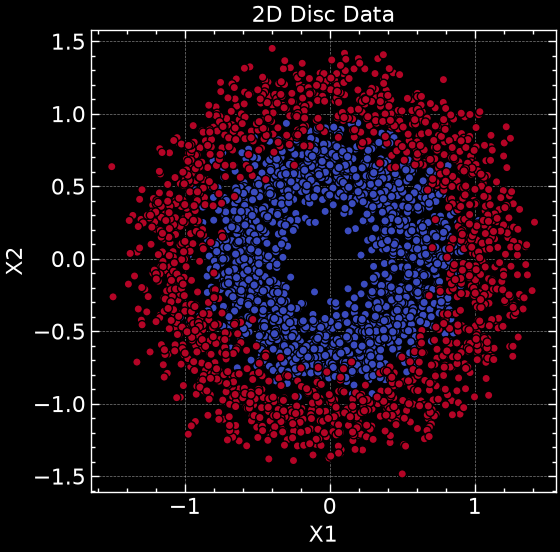

In [18]:
def plot_points_2d(X, y):
    
    plt.figure(figsize = (6, 6))
    plt.scatter(X[:, 0], X[:, 1], c = y, cmap = 'coolwarm', edgecolors = 'k')
    
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.title('2D Disc Data')
    plt.axis('equal')
    
    plt.show()

X, y = make_hypersphere_data(key, n_samples = 3000, dim = 2, noise = 0.15)
plot_points_2d(X[:, :2], y)

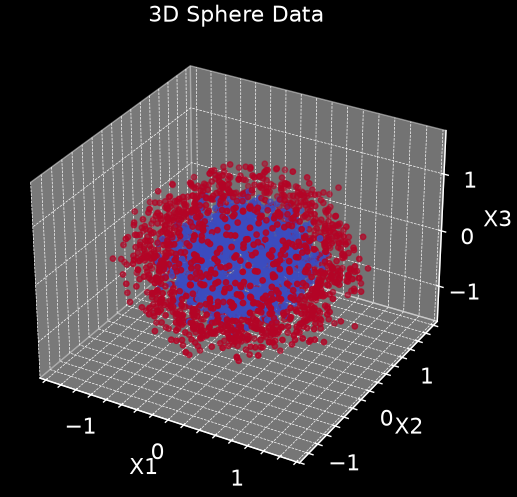

In [19]:
def plot_points_3d(X, y):
    
    ax = plt.figure().add_subplot(projection = '3d')
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c = y, cmap = 'coolwarm', s = 15)
    
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('X3')
    ax.title.set_text('3D Sphere Data')
    
    plt.show()

X, y = make_hypersphere_data(key, n_samples = 3000, dim = 3, noise = 0.15)
plot_points_3d(X, y)

This is just for visualization; in practice, we can work with much higher-dimensional data. The key takeaway is that our dataset has a non-linear decision boundary, basically a concentric disk, sphere, hypersphere and so on. We have separability! Now before proceeding, lets redefine our dataset with higher dimensions and a similar amount of points for practicality:

In [34]:
X, y = make_hypersphere_data(key, n_samples = 200, dim = 7, noise = 0.001)

Now let's compare the QFMs on this dataset. We'll compute the kernel matrices for each feature map and visualize them. The kernel matrix, as a reminder, contains the inner products between all pairs of data points in the quantum feature space. By visualizing these matrices, we can see how well each feature map separates the data points based on their labels.

You probably have a tierlist in mind by now, but let's see how they actually perform!

In [35]:
X = np.asarray(X)

num_features = X.shape[1]

zfm = z_feature_map(
    
    feature_dimension = num_features,
    reps = 1

)

zzfm = zz_feature_map(

    feature_dimension = num_features,
    reps = 1

)

pfm = pauli_feature_map(

    feature_dimension = num_features,
    paulis = ['X', 'Y', 'ZZ'],
    reps = 1

)

`reps = 1` is deliberate here to keep the circuits shallow and manageable for simulation. `paulis = ['X', 'Y', 'ZZ']` is set for fair comparison. After this step, you could change the number of repetitions to see how it scales with computation time and performance.

# 3. Kernel Matrix Computation

We can now define our quantum kernels using the feature maps we created earlier. The `FidelityQuantumKernel` class computes the kernel matrix based on the fidelity (inner product) between quantum states generated by the feature maps.

In [36]:
kernel_z = FidelityQuantumKernel(feature_map = zfm)
kernel_zz = FidelityQuantumKernel(feature_map = zzfm)
kernel_p = FidelityQuantumKernel(feature_map = pfm)

In [37]:
start = time.perf_counter()

K_z  = kernel_z.evaluate(X)
K_zz = kernel_zz.evaluate(X)
K_p  = kernel_p.evaluate(X)

end = time.perf_counter()

print(f'Kernel evaluation time: {end - start:.3f} seconds')

Kernel evaluation time: 234.144 seconds


The time difference should be pretty stark. Simulating quantum circuits on your machine can be quite slow, especially as the number of qubits and circuit depth increases. I can plot a relationship between number of dimensions = number of qubits, and computation time to illustrate this point. Choose your dimension range, number of points (ideally very low, the scaling isn't affected too much beyond a two-digit value), and your feature map.

Dimension = 2, Time elapsed = 1.746s
Dimension = 3, Time elapsed = 3.090s
Dimension = 4, Time elapsed = 5.091s
Dimension = 5, Time elapsed = 8.028s
Dimension = 6, Time elapsed = 13.400s


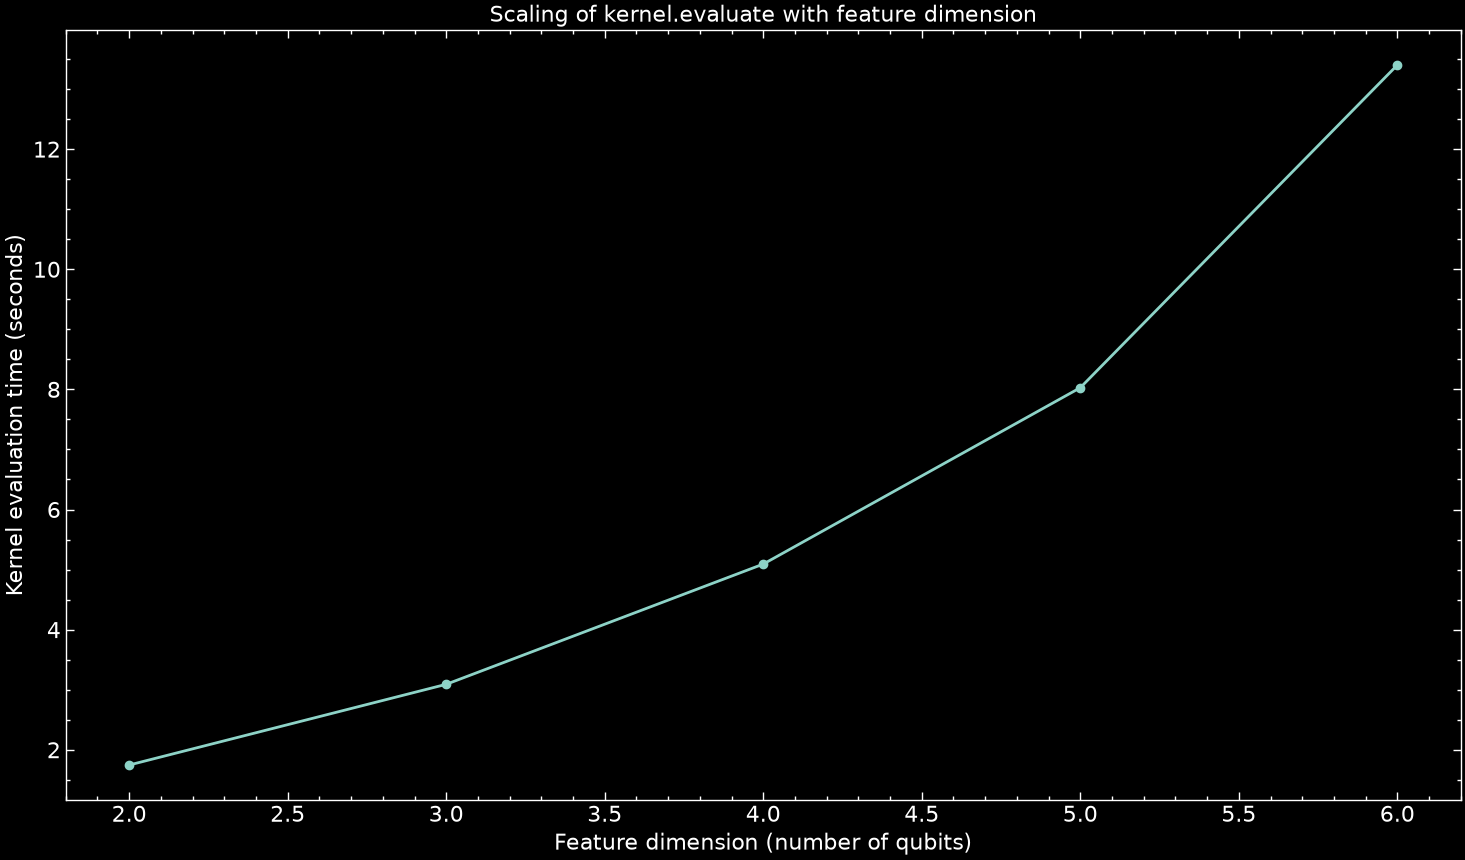

In [25]:
n = 100
dims = [i for i in range(2, 6 + 1)]  # Start from 2, edit upper bound as you please

times = []

for d in dims:
    
    X_dim, y_dim = make_hypersphere_data(key, n_samples = n, dim = d, noise = 0.15)
    X_dim = np.asarray(X_dim)
    
    featuremap_d = zz_feature_map(feature_dimension = d, reps = 1)
    kernel = FidelityQuantumKernel(feature_map = featuremap_d)
    
    start = time.perf_counter()
    kernel.evaluate(X_dim)
    elapsed = time.perf_counter() - start
    
    times.append(elapsed)
    print(f'Dimension = {d}, Time elapsed = {elapsed:.3f}s')

plt.figure(figsize = (18, 10))
plt.plot(dims, times, marker = 'o')

plt.title('Kernel Evaluation Time vs. Feature Dimension')
plt.xlabel('Feature dimension (number of qubits)')
plt.ylabel('Kernel evaluation time (seconds)')

plt.title('Scaling of kernel.evaluate with feature dimension')
plt.grid()

The expectation is something like $O(N^2\cdot 2^d)$, where $N$ is the number of points and $d$ is the dimension. $N^2$ acts as a persistent multiplier while $2^d$ explodes quickly.

That aside, now we can visualize the kernel matrices for each feature map. Ideally, we want to see clear blocks of high similarity (bright areas) for points within the same class and low similarity (dark areas) between different classes.

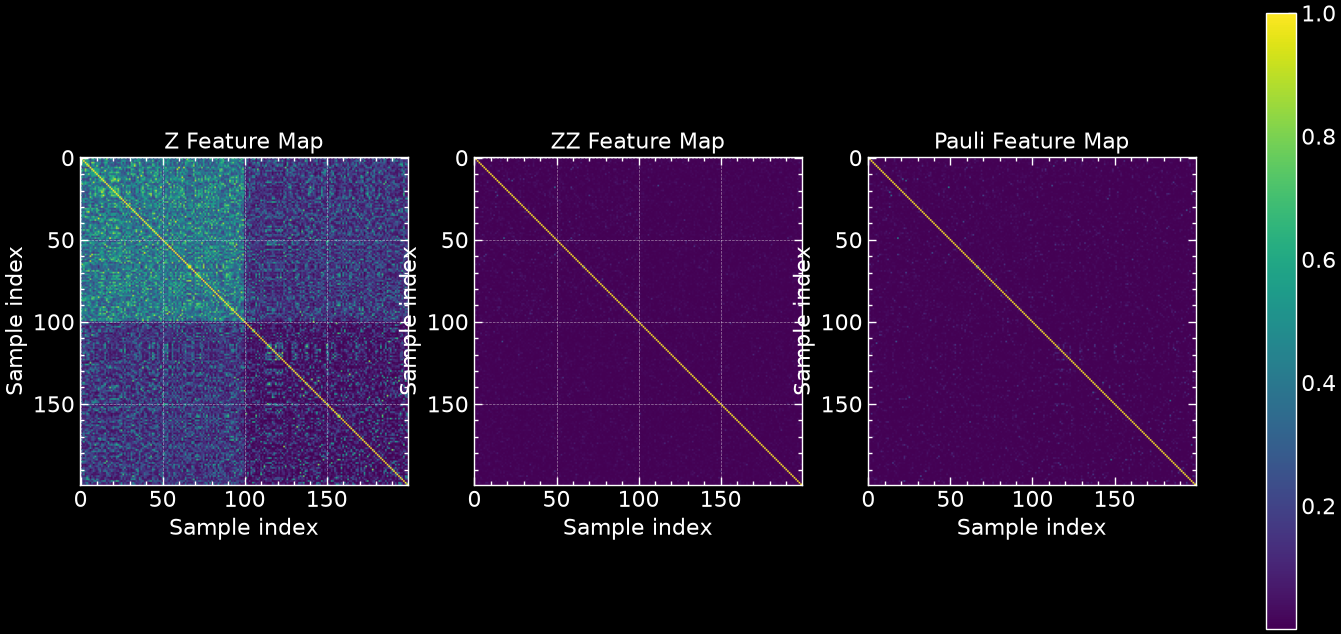

In [38]:
fig, axes = plt.subplots(1, 3, figsize = (18, 10))

for ax, K, title in zip(

    axes,
    [K_z, K_zz, K_p],
    ['Z Feature Map', 'ZZ Feature Map', 'Pauli Feature Map']

):
    
    im = ax.imshow(K, cmap = 'viridis')
    
    ax.set_title(title)
    ax.set_xlabel('Sample index')
    ax.set_ylabel('Sample index')

fig.colorbar(im, ax = axes, shrink = 0.8)

plt.grid()
plt.show()

Now, how do we read these plots? What we're seeing is a bright diagonal line, which indicates that each data point is most similar to itself, as expected. The off-diagonal elements represent the similarity between different data points. Bright blocks off the diagonal would indicate that points from the same class are similar, very very pronounced in ZFM's topleft quadrant and very slightly in the others. 

Another aspect is noise, represented by data density variations. ZFM is very noisy in this regard, while PFM is the least. ZZFM is much sharper and cleaner than ZFM, likely due to the pairwise entanglement capturing correlations better. One could argue that PFM might be too sharp or over-resolved, potentially leading to overfitting in a real classification task. ZZFM is the winner for this dataset!

A note on hardware execution: My illustrative method of teaching is pretty incompatible with running on hardware for a few reasons, mainly due to the fact that the code structure is pretty ugly and unsuitable for our figurative learning purposes. Aside from this, the code took longer than 10 minutes on an Open Plan, not ideal for demonstration anyway. What we did on native student machines is clean, straightforward and easy to replicate on any modern CPU/GPU. 

If you're willing, there are of course tutorials with professionally cited datasets and computational methods that *require* hardware. Feel free to explore - this notebook is just a jumping-off point.

# 4. Training a Classical SVM

An SVM or *Support Vector Machine* is a classical machine learning algorithm used for classification tasks. It works by finding the optimal hyperplane that separates data points of different classes in a high-dimensional space. In our case, we'll use the kernel matrices computed from our quantum feature maps to train the SVM.

The quantum part (kernel construction) was done by the QFM, and all the SVM does is classify the data points based on the kernel matrix computed from the quantum feature map. Think of this step like classical post-processing and optimization after say, a quantum variational method.

The intellectual idea is basically solving $$\text{minimize}_\alpha\,\,\frac{1}{2}\sum_{i,j=1}^M \alpha_i\alpha_j y_i y_j K(x_i,x_j) - \sum_{i=1}^M \alpha_i$$ where $\alpha_i$ are Lagrange multipliers, $y_i$ are the class labels, and $K(x_i,x_j)$ is the kernel function. The goal is to find the optimal values of $\alpha_i$ that maximize the margin between the classes while minimizing classification errors.

Recapping or briefly introducing for the uninitiated, *Lagrange multipliers* are a mathematical tool used in optimization problems to find the extrema of a function subject to certain constraints. In the context of SVMs, they help us find the optimal plane or hyperplane that separates the classes while satisfying the constraints imposed by the data points.

Don't worry if this equation looks like gibberish right now; the key takeaway is that SVMs solve this equation to find the best way to separate the classes based on the kernel matrix we computed earlier. Now JAX has a sub-library called 'jaxopt' that provides optimization routines, including SVMs. We'll use this library to train our SVM on the quantum kernel matrices.

In [39]:
def svm_dual_objective(alpha, kernel_matrix):
    
    return 0.5 * alpha @ kernel_matrix @ alpha - jnp.sum(alpha)

This function called the *dual objective function* for the SVM, is just the optimizer for the function above. The goal is to minimize this function with respect to the Lagrange multipliers $\alpha$, given the kernel matrix. We use dot products (@ operator in JAX) for matrix multiplication here for efficiency. For the kernel matrix we can use the top dog, ZZFM.

In [40]:
y = jnp.array(y)
K_zz = jnp.asarray(K_zz)

Q = jnp.outer(y, y) * K_zz
Q

Array([[ 1.0000000e+00,  1.0917419e-02,  7.5499150e-03, ...,
        -1.9472199e-03, -4.9119485e-03, -2.0021698e-02],
       [ 1.0917419e-02,  1.0000000e+00,  4.5770919e-03, ...,
        -1.7911013e-03, -7.9541774e-03, -2.6551393e-04],
       [ 7.5499150e-03,  4.5770919e-03,  1.0000000e+00, ...,
        -8.1287464e-03, -1.9173419e-02, -9.9741053e-03],
       ...,
       [-1.9472199e-03, -1.7911013e-03, -8.1287464e-03, ...,
         1.0000000e+00,  4.6613004e-05,  1.6504912e-02],
       [-4.9119485e-03, -7.9541774e-03, -1.9173419e-02, ...,
         4.6613004e-05,  1.0000000e+00,  1.0339897e-02],
       [-2.0021698e-02, -2.6551393e-04, -9.9741053e-03, ...,
         1.6504912e-02,  1.0339897e-02,  1.0000000e+00]], dtype=float32)

I'll clear up the Q-K confusion promptly. Here, $K$ is the kernel matrix we computed earlier, and $Q$ is the **modified** kernel matrix that incorporates the class labels $y_iy_j$. Specifically, $Q_{ij} = y_i y_j K_{ij}$, where $y_i$ and $y_j$ are the labels for data points $i$ and $j$. This modification is crucial for the SVM optimization process, as it ensures that the optimization takes into account the class labels when determining the optimal hyperplane.

I talked about constraints earlier. In SVMs, we have a primary *box constraint* that ensures the Lagrange multipliers $\alpha_i$ are non-negative and bounded by a regularization parameter $C$: $0\leq \alpha_i \leq C$. This constraint helps prevent overfitting by limiting the influence of individual data points on the decision boundary. You can define $C$ yourself, but I'd recommend starting with 1.

In [41]:
C = 1.0

projection = lambda a, _: jnp.clip(a, 0.0, C)

Now we can set up the SVM optimizer using JAXopt's `ProjectedGradient` class. This class allows us to define the objective function, constraints, and optimization parameters. We'll initialize the Lagrange multipliers $\alpha$ to zeros and set a maximum number of iterations for the optimization process.

In [42]:
solver = ProjectedGradient(
    
    fun = svm_dual_objective,
    projection = projection,
    maxiter = 2000,
    tol = 1e-8

)

alpha0 = jnp.zeros(len(y))
solution = solver.run(init_params = alpha0, kernel_matrix = Q)

alpha = solution.params
alpha

Array([0.70016706, 0.9195962 , 1.        , 0.99674153, 1.        ,
       1.        , 0.7771119 , 0.90880597, 1.        , 1.        ,
       0.7195805 , 0.89337385, 1.        , 0.89653784, 0.71955466,
       0.8136655 , 0.81010747, 1.        , 0.7782602 , 0.92013735,
       0.8260534 , 0.75845087, 1.        , 0.57016027, 0.89800334,
       0.9126837 , 0.9150562 , 1.        , 0.6839195 , 0.85926175,
       0.67643505, 0.7497759 , 1.        , 0.7325338 , 0.9431207 ,
       1.        , 0.5057533 , 0.74042946, 0.9131062 , 0.93837124,
       0.9421835 , 0.89027345, 1.        , 0.7413721 , 1.        ,
       1.        , 0.8652675 , 0.90911585, 1.        , 0.69850063,
       0.91497874, 0.91709805, 0.59313023, 1.        , 0.90153676,
       1.        , 0.88559294, 0.89540005, 0.8731475 , 0.62675136,
       0.7476644 , 0.9321888 , 0.5721943 , 0.6813874 , 0.787485  ,
       0.84517705, 0.9713498 , 1.        , 0.83020526, 0.9560125 ,
       0.74625075, 1.        , 0.7414938 , 1.        , 0.78093

The cost is classical, there's no quantum part here. The expectation here with datapoints is $\mathcal O(M^2)$ per iteration, so it should only take seconds. If it doesn't, there's likely an issue.

# 5. Evaluating Performance

If you feel like cross-verifying the results, we can utilize a decision function used for training, though we're not training anything here per se. The decision function computes the weighted sum of the kernel evaluations between a new data point and all training data points, weighted by the Lagrange multipliers and class labels. The sign of this sum determines the predicted class label for the new data points. Mathematically, it's $$f(x) = \sum_{i=1}^M \alpha_i y_i K(x_i, x)$$

In [43]:
decision_values = jnp.sum(alpha * y * K_zz, axis = 1)
y_predicted = jnp.sign(decision_values)

accuracy = jnp.mean(y_predicted == y)
accuracy

Array(1., dtype=float32)

Better than expected! We could also check convergence of the optimizer by looking at the `solution.state` attribute, which contains information about the optimization process, including the number of iterations taken and whether convergence was achieved.

In [44]:
print(solution.state)

ProxGradState(iter_num=Array(2000, dtype=int32, weak_type=True), stepsize=Array(1., dtype=float32), error=Array(5.623091e-07, dtype=float32), aux=None, velocity=Array([0.70016706, 0.9195962 , 1.        , 0.9967416 , 1.        ,
       1.        , 0.7771119 , 0.908806  , 1.        , 1.        ,
       0.7195805 , 0.89337397, 1.        , 0.8965378 , 0.71955466,
       0.8136655 , 0.81010747, 1.        , 0.7782601 , 0.9201373 ,
       0.8260533 , 0.75845075, 1.        , 0.57016027, 0.8980032 ,
       0.9126836 , 0.9150562 , 1.        , 0.6839195 , 0.85926163,
       0.67643505, 0.7497759 , 1.        , 0.7325338 , 0.94312066,
       1.        , 0.50575334, 0.7404294 , 0.9131062 , 0.93837136,
       0.9421835 , 0.89027345, 1.        , 0.7413722 , 1.        ,
       1.        , 0.8652676 , 0.9091158 , 1.        , 0.69850063,
       0.91497874, 0.91709805, 0.59313023, 1.        , 0.90153676,
       1.        , 0.88559294, 0.89540005, 0.87314755, 0.6267515 ,
       0.7476644 , 0.93218887, 0.57

Lastly, we can look at the hyperplane; decision value vs latent variable $r=\sqrt{x_1^2+x_2^2+\cdots+x_n^2}$ (remember, that's our radius of the hypersphere). Did the quantum kernel manage to uncover the hidden structure that defines the labels? If it did, we should see a clear separation in the decision values corresponding to the two classes, and decision value should behave smoothly and monotonically with $r$.

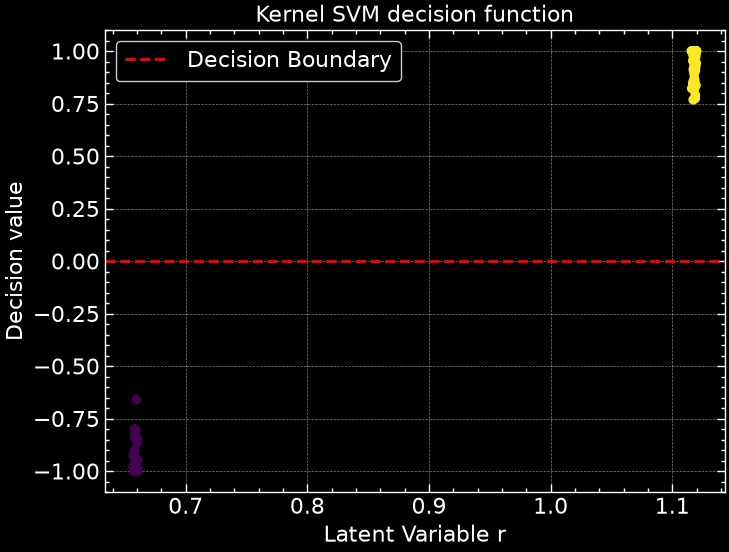

In [45]:
r = jnp.linalg.norm(X, axis = 1)

plt.scatter(r, decision_values, c = y)
plt.axhline(0, color = 'r', linestyle = '--', label = 'Decision Boundary')

plt.xlabel('Latent Variable r')
plt.ylabel('Decision value')
plt.title('Kernel SVM decision function')
plt.legend()

Remember, this is just for ZZFM, but you can try the others too! Just replace the feature map identifier way back at the start of section 3.

ZZFM is the best after all! The decision values for the two classes are well-separated, with a clear decision boundary at 0. The decision values are also not erratic, showing a smooth transition as the radius increases. The quantum kernel has successfully rendered our data linearly separable in the quantum feature space (This is a 2-d projection of a higher-dimensional space after all).

***

And that's a wrap for this primer on Quantum Machine Learning with Qiskit! We've covered the basics of data encoding, quantum feature maps, kernel matrix computation, and training a classical SVM using quantum kernels. I hope this gives you a solid foundation to explore more advanced topics in quantum machine learning. I'd recommend checking out the [Qiskit Machine Learning documentation](https://qiskit-community.github.io/qiskit-machine-learning/index.html) as well as [IBM's course](https://quantum.cloud.ibm.com/learning/en/courses/quantum-machine-learning) for further learning. Happy coding!